<a href="https://colab.research.google.com/github/Aksce98/IT-Academy/blob/main/Sprint_9/Sprint_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Nivell 1 - Visualització analítica guiada en Python

Degut a que no tinc accés a MySQL ja que estic treballant desde una tablet Android, hauria d'utilitzar la base de dades de BigQuery. Malauradament, la base de dades de BigQuery ha expirat i ja no hi ha dades disponibles, per tant posaré el codi que s'hauria utilitzat si estiguessin les dades encara disponible pero utilizarem les dades directament des dels CSV disponibles al Sprint 2.

In [1074]:
BigQuery = False
if BigQuery:
  from google.cloud import bigquery
  from google.oauth2 import service_account
  from google.colab import auth

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [1075]:
if BigQuery:
  auth.authenticate_user()
  PROJECT_ID = "your_project_name"
  client = bigquery.Client(project=PROJECT_ID)

In [1076]:
if BigQuery:
  data = {}
  for ds in client.list_datasets():
      data[ds.dataset_id] = {
          tbl.table_id: client.list_rows(tbl.reference).to_dataframe()
          for tbl in client.list_tables(ds.reference)
      }
  # En aquest punt, 'data' conté tots els datasets i totes les taules, i només ens quedaria per simplicitat
  # Definir variables per les taules específiques que necessitessim substituint your_dataset_name i your_table_name
  df = data["your_dataset_name"]["your_table_name"]

Utilitzem els CSV del Sprint 2 per carregar les nostres dades.

In [1077]:
transactions = pd.read_csv('N1-Ex.8__transactions.csv', sep=';')
companies = pd.read_csv('N1-Ex.8__companies.csv', sep=',')
eu = pd.read_csv('N1-Ex.8__european_users.csv', sep=',')
us = pd.read_csv('N1-Ex.8__american_users.csv', sep=',')
users = pd.concat([eu, us], ignore_index=True)
users = users.set_index('id').sort_index().reset_index()
products = pd.read_csv('N1-Ex.8__products.csv', sep=',')

##Exercici 1: Preguntes analítiques directes (sense integracions complexes)

###Com evoluciona el nombre de transaccions al llarg del temps?

<Figure size 1000x500 with 0 Axes>

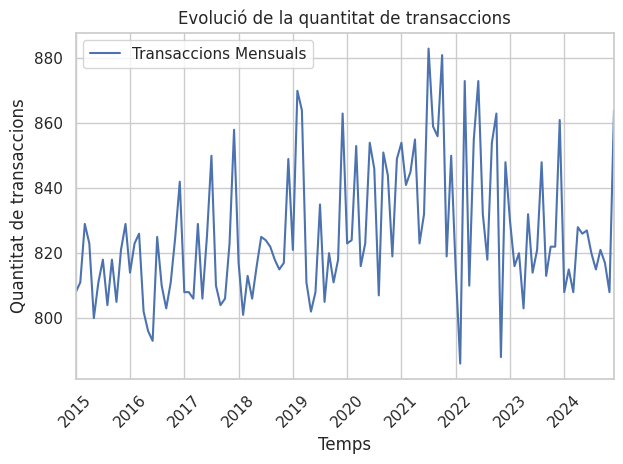

In [1078]:
transactions['timestamp'] = pd.to_datetime(transactions['timestamp'])

counts = transactions.query('declined == 0').groupby(transactions['timestamp'].dt.to_period('M')).size().reset_index(name='count')
counts['timestamp'] = counts['timestamp'].dt.to_timestamp()
period = 6
counts['rolling_mean'] = counts['count'].rolling(window=period, min_periods=1).mean()

plt.figure(figsize=(10, 5))
counts.plot(x='timestamp', y='count', kind='line', label='Transaccions Mensuals')
plt.title('Evolució de la quantitat de transaccions')
plt.xlabel('Temps')
plt.ylabel('Quantitat de transaccions')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

A simple vista el gràfic té valors que varien molt d'un més a l'altre, el que dificulta l'anàlisis ja que només es veu linies que pugen i baixen. Afegirem la mediana dels últims 6 mesos per reduïr la variabilitat del gràfic i poder observar amb més facilitat l'evolució temporal:

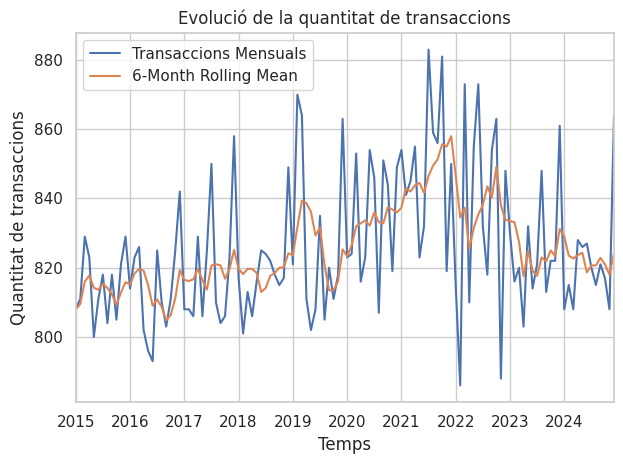

In [1079]:
ax = counts.plot(x='timestamp', y='count', kind='line', label='Transaccions Mensuals')
counts.plot(x='timestamp', y='rolling_mean', kind='line', ax=ax, label=f'{period}-Month Rolling Mean')

plt.title('Evolució de la quantitat de transaccions')
plt.xlabel('Temps')
plt.ylabel('Quantitat de transaccions')
plt.grid(True)
plt.tight_layout()
plt.show()

Tal i com podem observar, la quantitat de transaccións és bastant estable des del 2015 fins al 2018, on seguidament augmenta bastant a mitjans del 2019 i després torna a valors normals, però a l'inici del 2020 comença una tendència a l'alça fins aproximadament el 2022, on fa un efecte rebot i la quantiat de transaccions baixen, pujen i tornen a baixar fins a estabilitzar-se en valors una mica superiors als del primer període.

Versió amb Gemini:

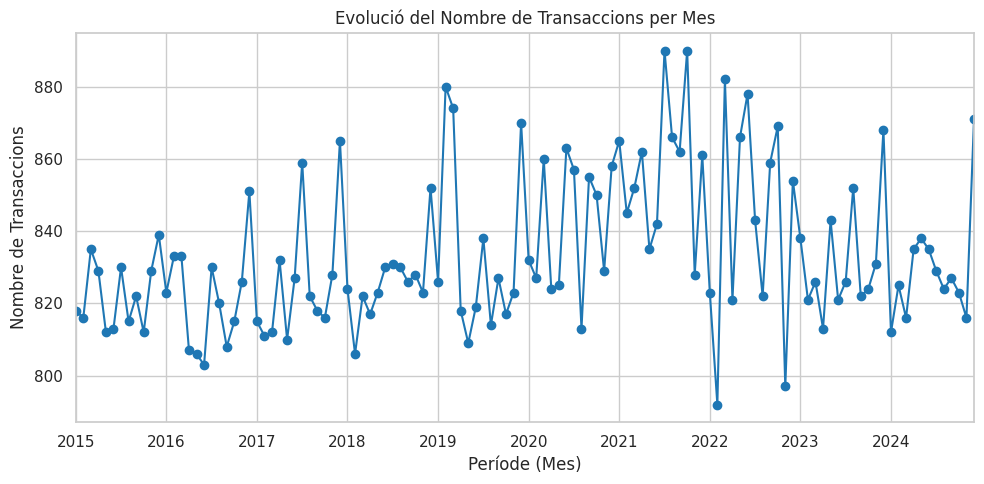

In [1080]:
# 1. Selecciona la columna temporal adequada i assegura't que té format datetime
transactions['timestamp'] = pd.to_datetime(transactions['timestamp'])

# 2. Defineix el nivell temporal d'anàlisi (per exemple, mensual) i compta els registres
evolucio_transaccions = transactions.groupby(transactions['timestamp'].dt.to_period('M')).size()

# 3. Ordena els resultats cronològicament
evolucio_transaccions = evolucio_transaccions.sort_index()

# 4. Visualitza l'evolució amb un gràfic de línies amb pandas
plt.figure(figsize=(10, 5))
evolucio_transaccions.plot(kind='line', marker='o', color='#1f77b4')
plt.title('Evolució del Nombre de Transaccions per Mes')
plt.xlabel('Període (Mes)')
plt.ylabel('Nombre de Transaccions')
plt.grid(True)
plt.tight_layout()
plt.show()

La versió amb Gemini és més ample i afegeix marcadors als valors. És visualment millor a la meva versió, però no afegeix el rolling mean i per tant no es pot valorar senzillament l'evolució com en el meu gràfic.

Quins usuaris generen més volum de facturacio?

<Axes: xlabel='user_id', ylabel='total_amount'>

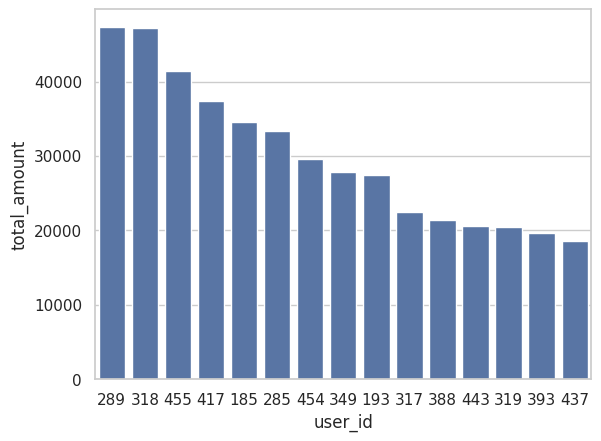

In [1081]:
transactions['amount'] = transactions['amount'].astype(float)

facturacio = transactions.groupby('user_id')['amount'].sum().reset_index(name='total_amount')
facturacio = facturacio.sort_values('total_amount', ascending=False).reset_index(drop=True)
usuaris = 15
top = facturacio.head(usuaris)

sns.barplot(x='user_id', y='total_amount', data=top, order=top['user_id'])

Versió amb Gemini:

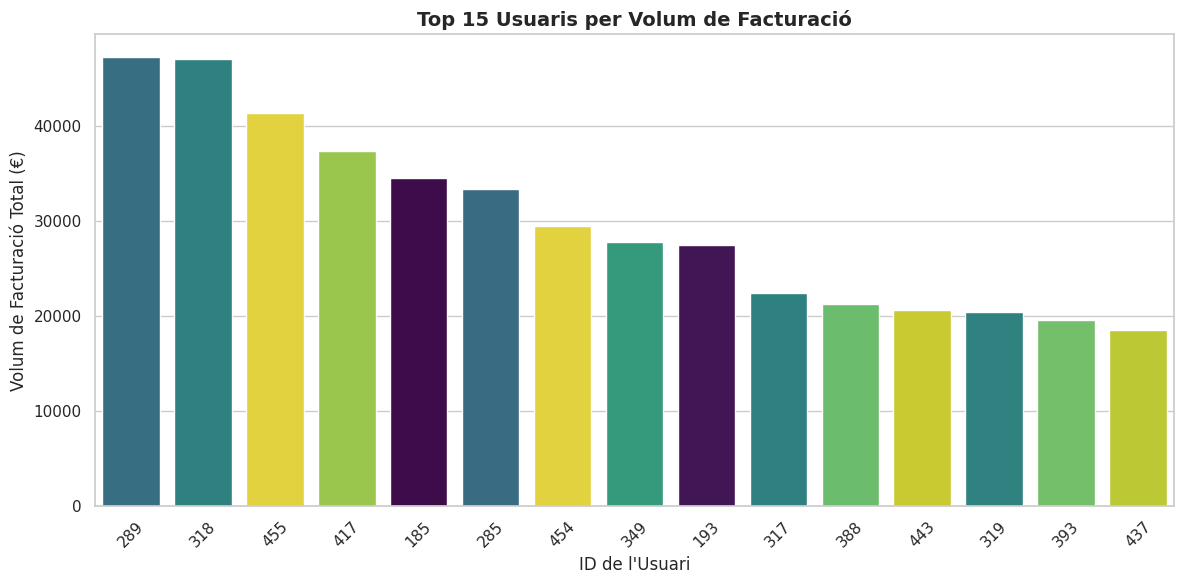

In [1082]:
# 1. Identifiquem la columna que representa l'usuari: 'user_id'
# 2. Agrupem les transaccions per usuari i calculem el volum total de facturació sumant 'amount'
facturacio_usuaris = transactions.groupby('user_id')['amount'].sum().reset_index(name='total_amount')

# 3. Ordenem els usuaris de major a menor volum de facturació
facturacio_usuaris = facturacio_usuaris.sort_values(by='total_amount', ascending=False)

# 4. Seleccionem els 15 usuaris principals
top_15_usuaris = facturacio_usuaris.head(15)

# 5. Representem el resultat mitjançant un gràfic de barres utilitzant Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(
    x='user_id',
    y='total_amount',
    data=top_15_usuaris,
    order=top_15_usuaris['user_id'],
    palette='viridis',
    hue='user_id',
    legend=False
)

plt.title('Top 15 Usuaris per Volum de Facturació', fontsize=14, fontweight='bold')
plt.xlabel('ID de l\'Usuari', fontsize=12)
plt.ylabel('Volum de Facturació Total (€)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Gemini afegeix colors diferents a cada columna, amplia la mida horitzontal del gràfic i afegeix els títols del gràfic i eixos.
És millor visualment que el meu gràfic ja que principalment per els noms dels eixos i del gràfic, ja que els colors individuals a les columnes no aporten cap millora visible.

Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades?

<Axes: xlabel='hora', ylabel='amount'>

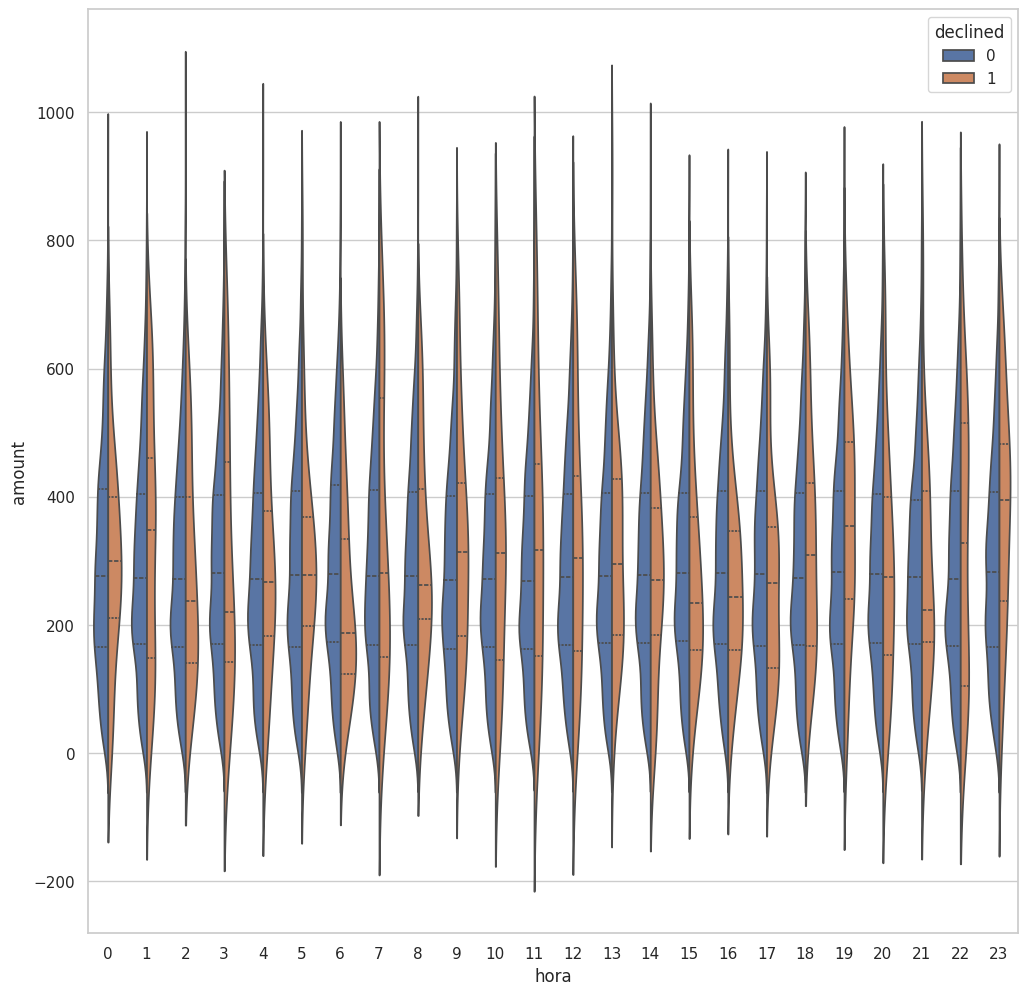

In [1083]:
transactions['hora'] = transactions['timestamp'].dt.hour

plt.figure(figsize=(12, 12))
sns.violinplot(data=transactions, x='hora', y='amount', hue='declined', split=True, inner='quart')

No s'observen diferències significants en els imports de les transaccions en les diferents hores ni en l'acceptació/rebujt d'aquests.

Versió amb Gemini:

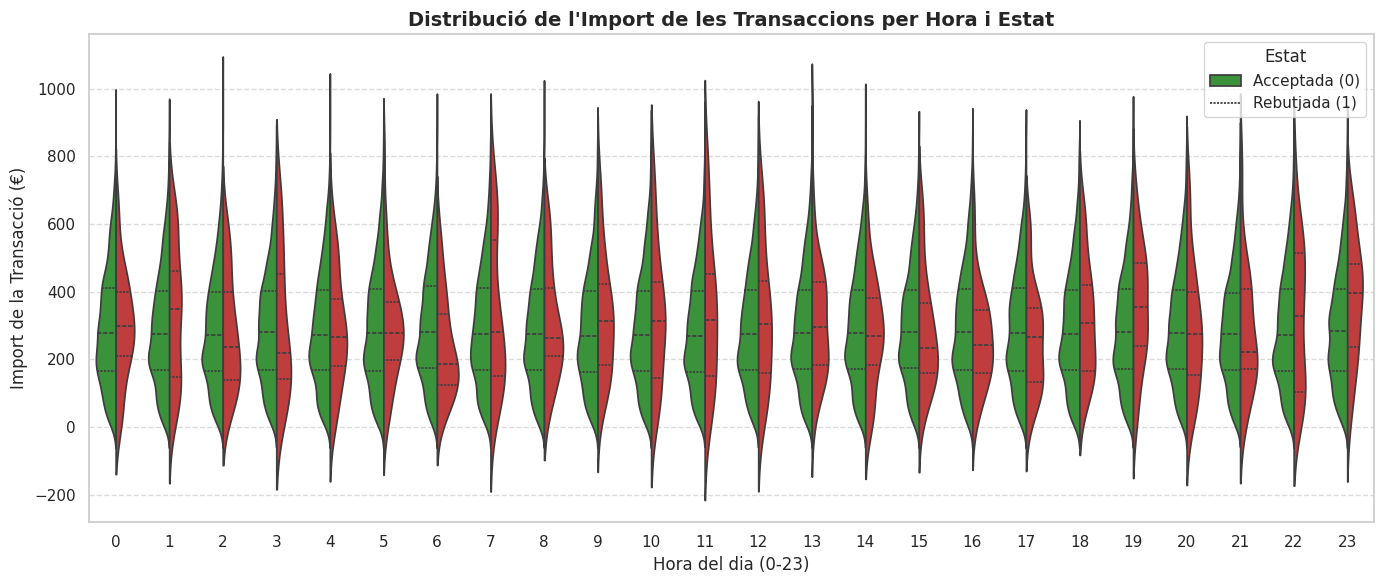

In [1084]:
# 1. Creem una nova columna amb l'hora del dia a partir del timestamp
transactions['hora'] = transactions['timestamp'].dt.hour

# 2. Configurem la mida de la figura per a una visualització clara
plt.figure(figsize=(14, 6))

# 3. Utilitzem un violinplot de seaborn per analitzar la distribució dels imports
sns.violinplot(
    data=transactions,
    x='hora',
    y='amount',
    hue='declined',
    split=True,
    inner='quartile',
    palette={0: '#2ca02c', 1: '#d62728'}  # Verd per acceptades, vermell per rebutjades
)

# 4. Personalitzem i millorem el gràfic
plt.title("Distribució de l'Import de les Transaccions per Hora i Estat", fontsize=14, fontweight='bold')
plt.xlabel("Hora del dia (0-23)", fontsize=12)
plt.ylabel("Import de la Transacció (€)", fontsize=12)

# Ajustem la llegenda per fer-la més explicativa
plt.legend(title="Estat", labels=['Acceptada (0)', 'Rebutjada (1)'], loc='upper right')

plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Gemini esculleix una paleta de colors diferent, verd per transaccions acceptades i vermell per transaccions declinades. A més, comprimeix més el gràfic verticalment i afegeix els noms dels eixos i del gràfic.
És millor que la meva versió ja que els colors són més adecuats per un cas com aquest (acceptació/rebutj) i el fet de que sigui més comprimit verticalment fa que càpiga en una sola pantalla sense haver de moure el gràfic verticalment per veure-ho.

Quins dies de la setmana es concentra més activitat de venda?

Començarem extraient el dia de la setmana utilitzant dt.day_name(), seguidament farem un group by del count de les transaccions i ho mostrarem en un plot.

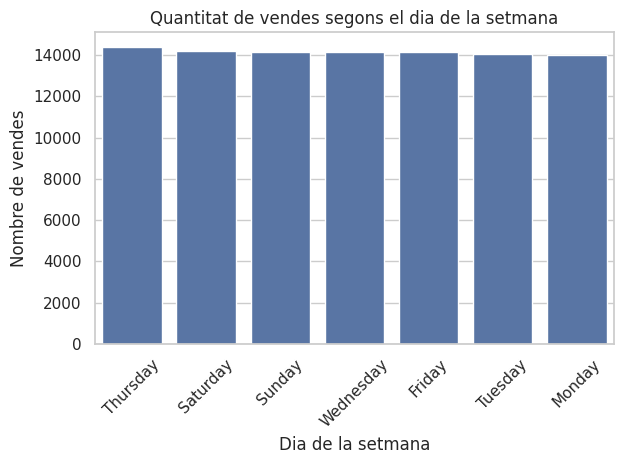

In [1085]:
transactions['weekday'] = transactions['timestamp'].dt.day_name()

counts = transactions.query('declined == 0').groupby(transactions['weekday']).size().reset_index(name='count')
counts = counts.sort_values('count', ascending=False).reset_index(drop=True)

sns.barplot(x='weekday', y='count', data=counts, order=counts['weekday'])
plt.title('Quantitat de vendes segons el dia de la setmana')
plt.xlabel('Dia de la setmana')
plt.ylabel('Nombre de vendes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Les vendes no es concentren en cap dia de la setmana, són pràcticament les mateixes vendes cada dia amb una variació extremadament petita des del dijous, on es les dades mostren més transaccions.

Versió amb Gemini:

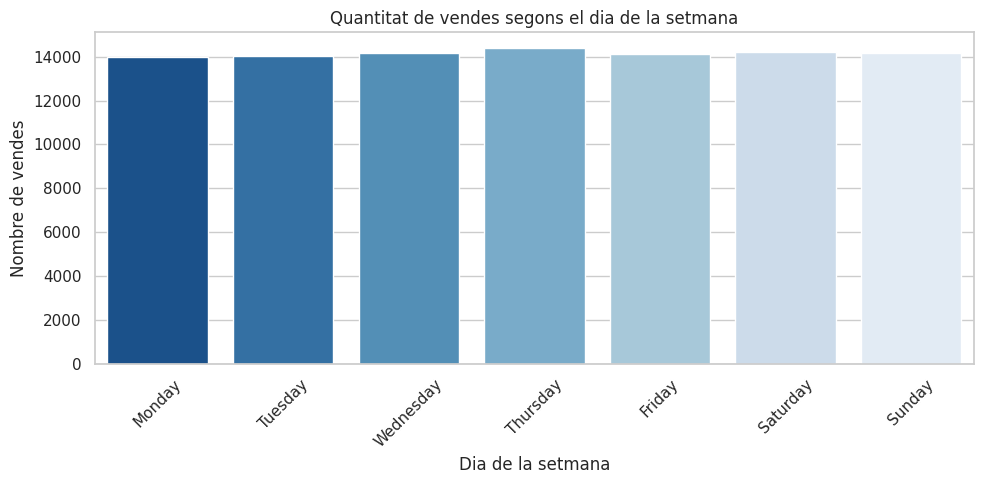

In [1086]:
# Definim l'ordre correcte dels dies de la setmana
ordre_dies = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Filtrem per transaccions acceptades (declined == 0) i agrupem per dia de la setmana
vendes_dia = transactions.query('declined == 0').groupby('weekday').size().reindex(ordre_dies).reset_index(name='vendes')

# Creem el gràfic de barres
plt.figure(figsize=(10, 5))
sns.barplot(x='weekday', y='vendes', data=vendes_dia, hue='weekday', palette='Blues_r')

# Personalitzem el gràfic
plt.title('Quantitat de vendes segons el dia de la setmana')
plt.xlabel('Dia de la setmana')
plt.ylabel('Nombre de vendes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

La resposta de Gemini és:

En general, no hi ha cap dia de la setmana on es concentri de forma desproporcionada l'activitat; el comportament de compra dels usuaris es manté molt estable dia a dia.

Si comparem les diferències entre la meva solució senzilla i la de Gemini, podem veure le següents diferències:
- El gràfic de Gemini està ordenat per dia de la setmana en comptes de quantitat de vendes.
- Hi ha un degradat de colors que no té cap sentit, ja que normalment es faria en funció de les vendes, però Gemini ho fa simplement d'esquerra a dreta (en funció del dia).
- Gemini ha afegit un títol al gràfic.

##Exercici 2: Preguntes analítiques complexes (amb guia)

###» Depenem excessivament d'un nombre reduït de països de companyies venedores?

In [1087]:
df = pd.merge(transactions, companies, left_on='business_id', right_on='company_id', how='inner')

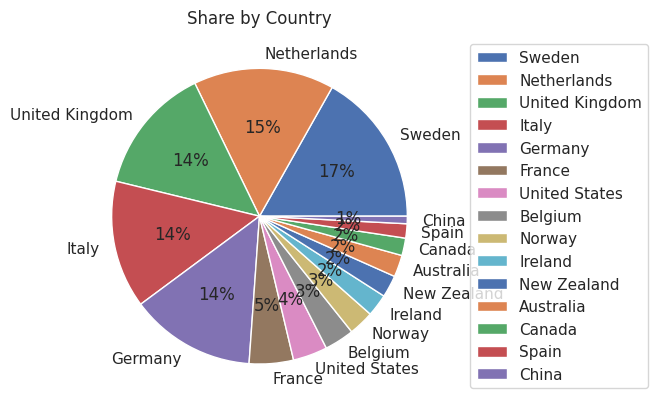

In [1088]:
result = df.groupby('country')['amount'].sum().reset_index().sort_values(by='amount',ascending=False, ignore_index=True)

total = result['amount'].sum()
result['share'] = result['amount'] / total

result.plot.pie(y='share', labels=result['country'], autopct=lambda x: f'{x:.0f}%')
plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.5))
plt.title('Share by Country')
plt.ylabel('')
plt.show()

En les nostres dades, hi ha 5 països amb un nivell de facturació molt superior a la resta de països. Suècia, Països Baixos, Regne Unit, Italia i Alemania juntament sumen un total de pràcticament tres quartes parts de la facturació.

###» Existeix estacionalitat en les vendes?

Crea una taula tipus pivot

In [1089]:
df = pd.DataFrame()
df['Year'] = transactions['timestamp'].dt.year
df['Month'] = transactions['timestamp'].dt.month
df['Amount'] = transactions['amount']
pivot_df = df.pivot_table(index='Year', columns='Month', values='Amount', aggfunc='sum')
pivot_df

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2015,224946.23,248775.83,254702.98,247957.49,252596.43,233084.63,243774.43,238550.36,227985.24,244420.98,228805.24,237169.43
2016,227231.14,251111.47,248245.83,242394.40,243533.92,233245.79,238618.15,238392.03,242774.67,251681.54,235185.22,237488.46
2017,224391.23,253354.90,240338.05,253125.97,240919.28,241065.64,244380.32,233894.55,235830.55,244385.66,243671.03,252058.49
2018,229524.09,246504.98,239145.90,237432.05,246838.08,243421.44,233449.29,231129.56,238772.22,257709.49,242636.18,234974.71
2019,224592.71,262006.66,280530.50,244347.66,244739.50,245470.13,233962.91,240040.21,235021.45,253133.66,233477.03,255307.10
2020,234191.13,249356.44,260821.35,246533.40,254171.48,238902.90,242644.23,234433.92,258779.26,260928.72,224595.34,246449.95
2021,246993.53,258837.10,253110.77,261597.02,243414.73,236504.81,253553.62,239433.71,247648.05,268417.75,242538.98,243737.57
2022,226680.93,237503.38,274387.47,241191.04,279590.23,261954.89,235935.19,246434.63,255496.48,258033.06,233416.07,239045.01
2023,231075.91,252680.15,243909.57,245386.83,264790.26,234527.22,240041.34,239288.98,237105.34,251431.72,235827.93,236690.04


Visualitzar l'evolució

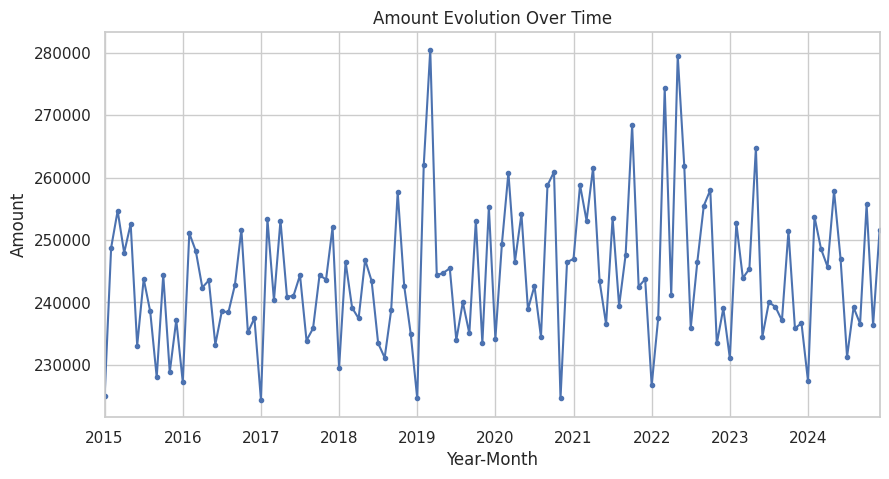

In [1090]:
transactions.set_index('timestamp').resample('ME')['amount'].sum().plot(kind='line', figsize=(10, 5), marker='.')

plt.title('Amount Evolution Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Amount')
plt.grid(True)
plt.show()


###» Anàlisi de concentració i variabilitat.
Opció B – Activitat d'usuaris

In [1091]:
df = transactions.sort_values(by='timestamp')
df = df.drop_duplicates(subset='user_id', keep='last')
df = df[['user_id', 'timestamp']]
now = pd.Timestamp.now()
df['elapsed'] = (now - df['timestamp']).dt.days / 7

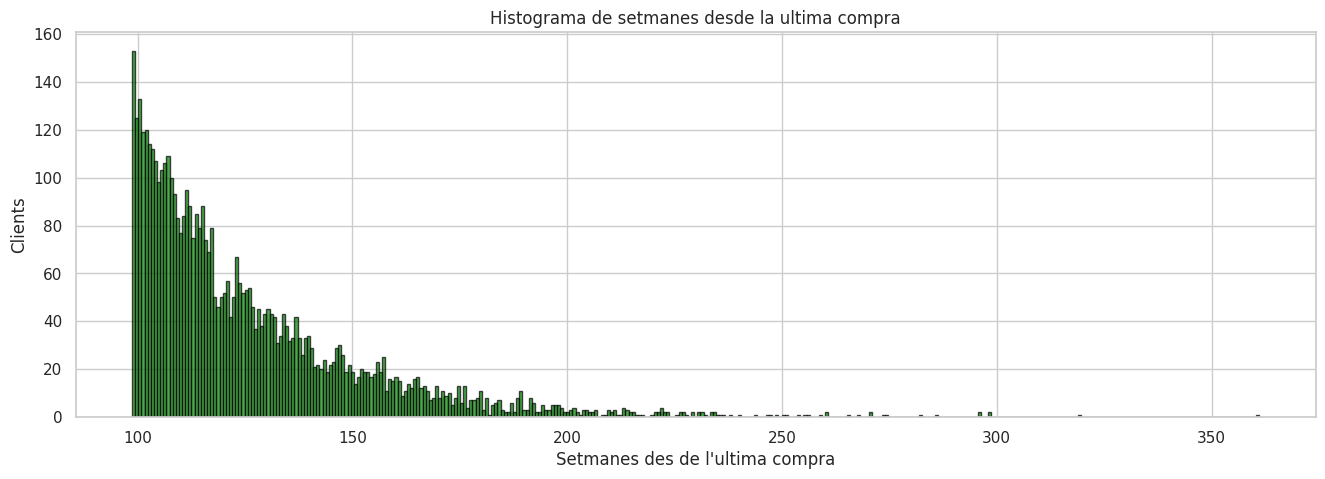

In [1092]:
n = df['elapsed'].max()
n = int(n)
ax = df['elapsed'].hist(bins=n, color='green', alpha=0.7, edgecolor='black')
ax.set_title('Histograma de setmanes desde la ultima compra')
ax.set_xlabel('Setmanes des de l\'ultima compra')
ax.set_ylabel('Clients')
ax.figure.set_size_inches(16, 5)
plt.show()

Hi ha usuaris que han deixat de comprar recentment?

No, tots els usuaris van deixar de comprar far temps, ja que la última transacció va ser el 2024, fa casi 100 setmanes pel que podem veure a l'histograma

###» Com varia l'activitat de venda per franges horàries al llarg dels anys? (patrons horaris)

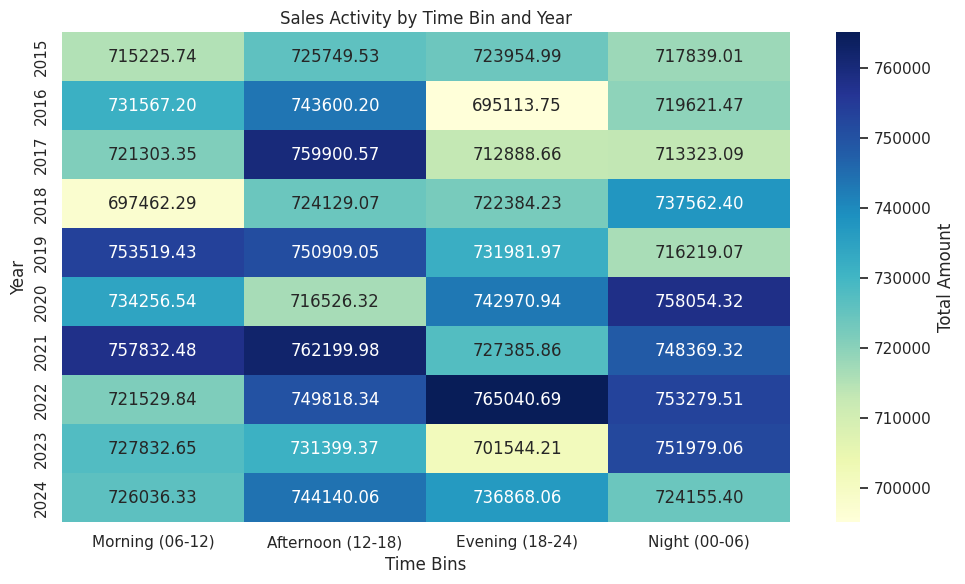

In [1093]:
def assign_time_bin(hour):
    if 6 <= hour < 12:
        return 'Morning (06-12)'
    elif 12 <= hour < 18:
        return 'Afternoon (12-18)'
    elif 18 <= hour < 24:
        return 'Evening (18-24)'
    else:
        return 'Night (00-06)'

df = pd.DataFrame()
df['amount'] = transactions['amount']
df['year'] = transactions['timestamp'].dt.year
df['hour'] = transactions['timestamp'].dt.hour
df['time_bin'] = df['hour'].apply(assign_time_bin)

ct = pd.crosstab(df['year'], df['time_bin'], values=df['amount'], aggfunc='sum').fillna(0)

time_order = ['Morning (06-12)', 'Afternoon (12-18)', 'Evening (18-24)', 'Night (00-06)']
ct = ct.reindex(columns=[col for col in time_order if col in ct.columns])

plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Total Amount'})
plt.title("Sales Activity by Time Bin and Year")
plt.xlabel("Time Bins")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


Analitzant el mapa de calor podem observar:
- Estabilitat: l'activitat de venda es manté molt homogènia tant al llarg dels anys com en les diferent franges horàries.
- Absència de patró: No s'observa cap franja horària dominant.

#Nivell 2 – Anàlisi relacional i patrons avançats

##Exercici 1: Anàlisi de productes i captació d'usuaris

###1. Combina les taules necessàries.

Creem la taula pont entre transactions i products, que ens permetrà treballar amb vendes individuals dels productes.

In [1094]:
transaction_product = (
  transactions[['id', 'product_ids']]
    .assign(product_ids=lambda x: x['product_ids'].str.split(','))
    .explode('product_ids')
    .assign(product_ids=lambda x: x['product_ids'].str.strip())
    .rename(columns={'product_ids': 'product_id'})
    .reset_index(drop=True)
    .rename(columns={'id':'transaction_id'})
)
transaction_product['product_id'] = pd.to_numeric(transaction_product['product_id'])
transactions = transactions.drop('product_ids', axis=1)

###2. Defineix un criteri de nou usuari si la transacció analitzada és la primera cronològicament que realitza al sistema es_nou_usuari = True / False.

Per identificar les primeres transaccions de cada usuari, simplement ordenem per timestamp de manera ascendent, eliminem tots el user_id duplicats i ens quedem amb la primera ocurrència, i seguidament utilitzem aquest subset de id per definiar es_nou_usuari a la taula principal.

In [1095]:
df = pd.DataFrame()
df = transactions[['id', 'timestamp', 'user_id']]
df = df.sort_values(['timestamp']).drop_duplicates(subset=['user_id'], keep='first')
transactions['es_nou_usuari'] = transactions['id'].isin(df['id'])

In [1096]:
products['price'] = pd.to_numeric(
  products['price'].str.replace(r'[$,]', '', regex=True)
)

### 3. Agrega la informació per producte i calcula les mètriques següents:

Fem un merge de products i transaction_products per afegir el preu dels productes a t_p i poder calcular els ingressos aggregats per producte.

In [1097]:
df = transaction_product.merge(
      products[['id', 'price']].rename(columns={'id': 'product_id'}),
      how='inner',
      on='product_id'
    ).merge(
      transactions[['id', 'es_nou_usuari']].rename(columns={'id': 'transaction_id'}),
      how='inner',
      on='transaction_id'
    )
df = df.groupby('product_id').agg(
    total_price=('price', 'sum'),
    nou_usuaris=('es_nou_usuari', 'sum'),
    total_transactions=('product_id', 'count')
).assign(percent_nou_usuaris=lambda x: x['nou_usuaris'] / x['total_transactions'])

### 4. Creació d'una tipologia analítica de productes a partir de les mètriques calculades, per exemple:

- Captador: alta captació de nous usuaris. Ho definirem com el top 25% de productes amb un percentatge de nous usuaris més alt i ingressos al top 25%.

In [1098]:
df['captador'] = (df['percent_nou_usuaris'] >= df['percent_nou_usuaris'].quantile(0.75)) & (df['total_price'] >= df['total_price'].quantile(0.75))

- Recurrent: ingressos elevats però baixa captació. Aquells productes no captadors, pero top 25% de productes amb facturació més gran.

In [1099]:
df['recurrent'] = (df['total_price'] >= df['total_price'].quantile(0.75)) & (df['captador'] == False)

- Emergent: baixa facturació però bona captació. Ho definirem com aquells productes que són captadors pero no tenen uns ingressos elevats.

In [1100]:
df['emergent'] = (df['percent_nou_usuaris'] >= df['percent_nou_usuaris'].quantile(0.75)) & (df['total_price'] < df['total_price'].quantile(0.75))

- Estancat: baixos ingressos i baixa captació. Ho definirem com aquells productes que no són captadors i no són recurrents.

In [1101]:
df['estancat'] = (df['captador'] == False) & (df['recurrent'] == False)

### 5. Construeix una visualització que permeti analitzar la relació entre les dimensions principals.

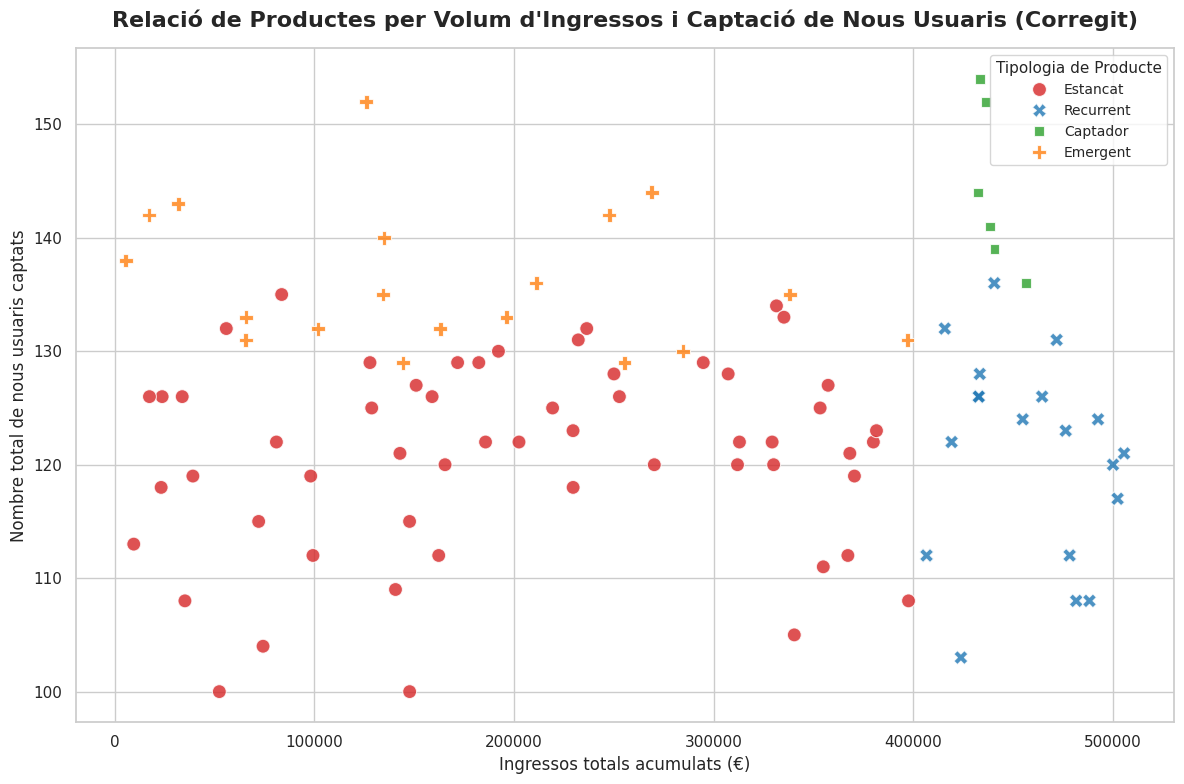

In [1102]:
df.loc[df['captador'] == True, 'tipologia'] = 'Captador'
df.loc[df['estancat'] == True, 'tipologia'] = 'Estancat'
df.loc[df['recurrent'] == True, 'tipologia'] = 'Recurrent'
df.loc[df['emergent'] == True, 'tipologia'] = 'Emergent'

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x='total_price',
    y='nou_usuaris',
    hue='tipologia',
    palette={'Captador': '#2ca02c', 'Recurrent': '#1f77b4', 'Emergent': '#ff7f0e', 'Estancat': '#d62728'},
    style='tipologia',
    s=100,
    alpha=0.8
)

plt.title('Relació de Productes per Volum d\'Ingressos i Captació de Nous Usuaris (Corregit)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Ingressos totals acumulats (€)', fontsize=12)
plt.ylabel('Nombre total de nous usuaris captats', fontsize=12)
plt.legend(title='Tipologia de Producte', title_fontsize='11', fontsize='10', loc='upper right')

plt.tight_layout()
plt.show()

En aquest gràfic podem veure la distribució de cada tipus de producte.
A la dreta trobem els productes amb ingressos més elevats, a la part superior trobem els productes amb major captació de nou usuaris, i si ens fixem amb més precisió, a la part superior dreta trobem els productes captadors, que tenen una bona captació i ingressos elevats, i a la part inferior-esquerra trobem els productes estancats, que no aconsegueixen captar nous clients ni aconsegueixen alts ingressos.

##Exercici 2: Anàlisi geogràfica company–usuari i oportunitats d'expansió

###1. Combina les taules necessàries.
Comencem fent un triple merge amb transactions, users i companyies per obtenir el pais de venda i de compra de cada transacció.

In [1103]:
df = pd.DataFrame()
df = pd.merge(
      transactions,
      companies[['company_id', 'country']].rename(columns={'company_id': 'business_id', 'country': 'company_country'}),
      how='inner',
      on='business_id'
    ).merge(
      users[['id', 'country']].rename(columns={'id': 'user_id', 'country': 'user_country'}),
      how='inner',
      on='user_id'
    )
# Eliminem transaccions no vàlides:
df = df[df['declined'] == False]

###2. Crea una variable clau d'anàlisi: compra_local = True/False.

In [1104]:
df['compra_local'] = df['user_country'] == df['company_country']

###3. Analitza el comportament global:
Percentatge de transaccions locals vs internacionals.

In [1105]:
transactions_percent = float((df['compra_local'].sum() / len(df) * 100))
print(f'El percentatge de transaccions locals és del: {round(transactions_percent,2)}%')
print(f'El percentatge de transaccions internacionals és del: {round(100 - transactions_percent,2)}%')

El percentatge de transaccions locals és del: 11.87%
El percentatge de transaccions internacionals és del: 88.13%


Percentatge de facturació local vs internacional.

In [1106]:
revenue_percent = (df.groupby('compra_local')['amount'].sum() / df['amount'].sum()) * 100
print(f'El percentatge de facturació local és del: {round(revenue_percent[True],2)}%')
print(f'El percentatge de facturació internacional és del: {round(revenue_percent[False],2)}%')

El percentatge de facturació local és del: 11.89%
El percentatge de facturació internacional és del: 88.11%


###4. Anàlisi per país de l'usuari, per cada país d'usuari:
% de compres a companyies del mateix país.

In [1107]:
user_data = (
    df.groupby('user_country')
    .agg(
        percent_same_country=('compra_local', lambda x: x.mean() * 100),
        percent_foreign_country=('compra_local', lambda x: (1 - x.mean()) * 100),
        total_amount=('amount', 'sum'),
    )
    .reset_index()
)

In [1108]:
user_data[['user_country','percent_same_country']].sort_values('percent_same_country', ascending=False)

,user_country,percent_same_country
8,Sweden,21.341766
4,Netherlands,19.361008
10,United States,18.548885
9,United Kingdom,17.291427
3,Italy,17.107273
2,Germany,16.953658
0,Canada,9.720670
1,France,6.281854
7,Spain,1.734039
6,Portugal,0.000000


% de compres a companyies estrangeres.

In [1109]:
user_data[['user_country','percent_foreign_country']].sort_values('percent_foreign_country', ascending=False)

,user_country,percent_foreign_country
6,Portugal,100.000000
5,Poland,100.000000
7,Spain,98.265961
1,France,93.718146
0,Canada,90.279330
2,Germany,83.046342
3,Italy,82.892727
9,United Kingdom,82.708573
10,United States,81.451115
4,Netherlands,80.638992



Import total comprat.

In [1110]:
user_data[['user_country','total_amount']].sort_values('total_amount', ascending=False)

,user_country,total_amount
10,United States,3049853.50
9,United Kingdom,2819917.93
7,Spain,2668434.76
4,Netherlands,2651840.50
0,Canada,2650339.29
6,Portugal,2615801.06
3,Italy,2585602.49
2,Germany,2550878.07
5,Poland,2491052.36
8,Sweden,2473822.29


###5. Anàlisi per país de companyia, per cada país de companyia calcula quina part de la seva facturació ve de:

Usuaris locals.
Usuaris estrangers.

In [1111]:
result = (
    pd.crosstab(
        index=df['company_country'],
        columns=df['compra_local'],
        values=df['amount'],
        aggfunc='sum',
        normalize='index',
    )
    * 100
)
result = result.sort_values(by=True, ascending=False)
result = result.rename(
    columns={True: 'Usuaris locals (%)', False: 'Usuaris estrangers (%)'}
)
result

compra_local,Usuaris estrangers (%),Usuaris locals (%)
company_country,,
United States,46.964949,53.035051
Canada,53.845059,46.154941
United Kingdom,87.979039,12.020961
Netherlands,88.404601,11.595399
Germany,88.854403,11.145597
France,89.068804,10.931196
Italy,89.151218,10.848782
Sweden,89.212033,10.787967
Spain,89.287020,10.712980


###6. Escull una visualització que expliqui clarament el fenòmen.

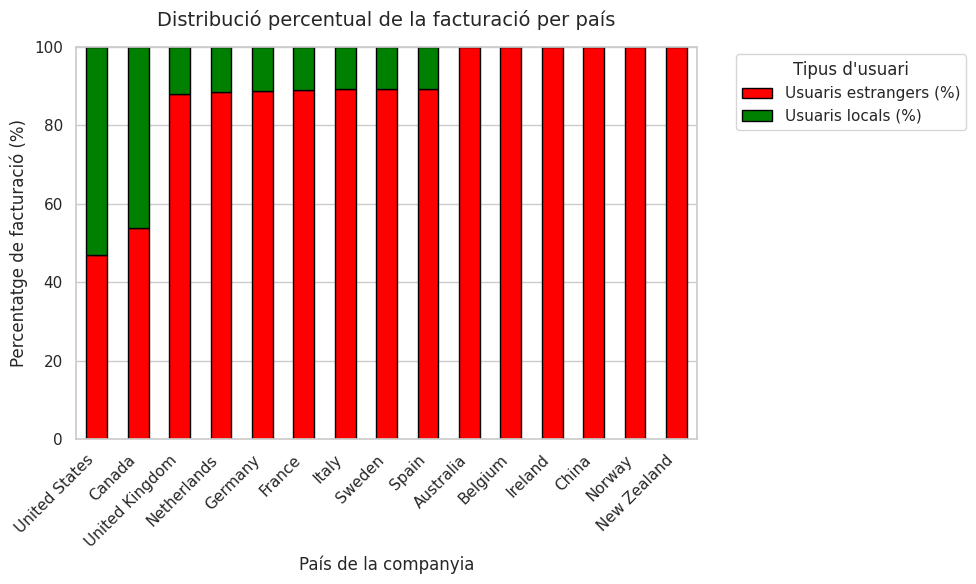

In [1112]:
ax = result.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=['red', 'green'],
    edgecolor='black',
)

plt.title(
    "Distribució percentual de la facturació per país",
    fontsize=14,
    pad=15,
)
plt.xlabel("País de la companyia", fontsize=12)
plt.ylabel("Percentatge de facturació (%)", fontsize=12)
plt.legend(
    title="Tipus d'usuari", bbox_to_anchor=(1.05, 1), loc='upper left'
)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

###7. Interpretació estratègica:
- En quins països valdria la pena obrir més companyies locals?

Valdria la pena obrir més companyies locals en aquells països que sempre compren a l'estranger, com Portugal, Polònia, Espanya o França, d'entre altres.
- Hi ha països amb demanda però poca oferta local?

Si, països com Espanya amb un import de compres que és el tercer més alt de tots i té un 98.27% realitzades a companyies estrangeres.
- El negoci depèn massa de companyies d'un sol país?


In [1113]:
df.groupby('company_country')['amount'].sum().sort_values(ascending=False) / df['amount'].sum()

,amount
company_country,
Sweden,0.168275
Netherlands,0.154033
United Kingdom,0.140053
Italy,0.139914
Germany,0.137282
France,0.048463
United States,0.037390
Belgium,0.032309
Norway,0.027505


No, el país amb les companyies més altes, Sweden, tan sols té un 16% de la facturació total, el qual no és massa elevat en comparació amb altres països com Netherlands, United Kingdom o Italy.
- Obrir companyies locals reduiria fricció o milloraria conversió?

En països on els usuaris sempre compren a l'estranger, tenir una companyia local donaria un avantatge molt elevat respecte a la competència.

#Nivell 3 - Visualització executiva i storytelling

##Exercici 1: Mini-dashboard departamental


Farem una única figura amb 4 subplots utilitzant seaborn. Els 4 gràfics que farem són:
- Evolució mensual de la facturació: sumem la facturació agrupada per més. Això ho representarem amb un gràfic de linies.
- Top països per facturació: sumem la facturació agrupada per país de venda. Això ho representarem amb un gràfic de barres.
- Transaccions acceptades vs declinades: un gràfic de pastís mostrant el % de transaccions acceptades i declinades.
- Vendes per dia de la setmana: sumem la facturació agrupada per día de la setmana. Això ho mostrarem en un gràfic de barres.

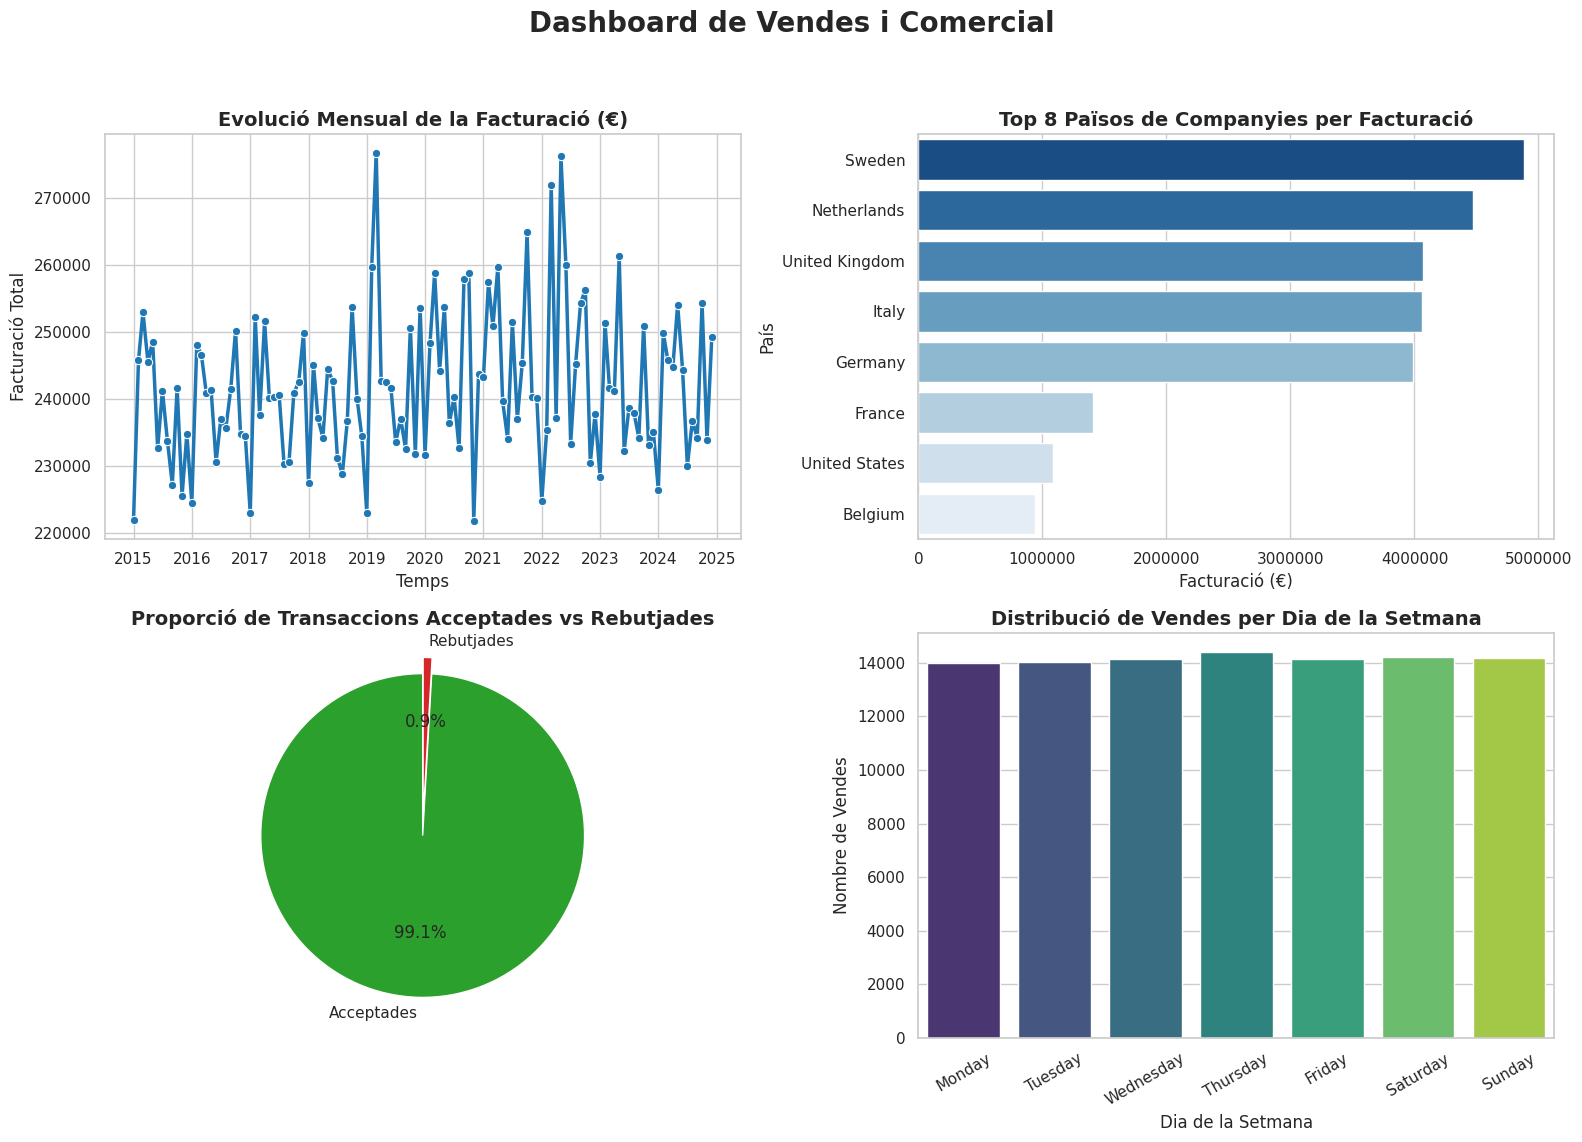

In [1114]:
# Definim l'estil general
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Dashboard de Vendes i Comercial", fontsize=20, fontweight='bold', y=0.95)

# 1. Evolució mensual de la facturació
sales_evolution = transactions.query('declined == 0').copy()
sales_evolution['month'] = sales_evolution['timestamp'].dt.to_period('M').dt.to_timestamp()
monthly_sales = sales_evolution.groupby('month')['amount'].sum().reset_index()

sns.lineplot(ax=axes[0, 0], data=monthly_sales, x='month', y='amount', color='#1f77b4', linewidth=2.5, marker='o')
axes[0, 0].set_title("Evolució Mensual de la Facturació (€)", fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel("Temps")
axes[0, 0].set_ylabel("Facturació Total")

# 2. Top Països per Volum de Facturació
country_sales = df.groupby('company_country')['amount'].sum().reset_index().sort_values(by='amount', ascending=False).head(8)

sns.barplot(ax=axes[0, 1], data=country_sales, x='amount', y='company_country', palette='Blues_r', hue='company_country', legend=False)
axes[0, 1].set_title("Top 8 Països de Companyies per Facturació", fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel("Facturació (€)")
axes[0, 1].set_ylabel("País")
axes[0, 1].ticklabel_format(style='plain', axis='x')

# 3. Estat de les Transaccions: Acceptades vs Rebutjades
trans_status = transactions['declined'].value_counts().reset_index()
trans_status['declined'] = trans_status['declined'].map({0: 'Acceptades', 1: 'Rebutjades'})

axes[1, 0].pie(trans_status['count'], labels=trans_status['declined'], autopct='%1.1f%%', startangle=90, colors=['#2ca02c', '#d62728'], explode=(0, 0.1))
axes[1, 0].set_title("Proporció de Transaccions Acceptades vs Rebutjades", fontsize=14, fontweight='bold')

# 4. Volum de Vendes per Dia de la Setmana
ordre_dies = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
vendes_dia = transactions.query('declined == 0').groupby('weekday').size().reindex(ordre_dies).reset_index(name='vendes')

sns.barplot(ax=axes[1, 1], data=vendes_dia, x='weekday', y='vendes', palette='viridis', hue='weekday', legend=False)
axes[1, 1].set_title("Distribució de Vendes per Dia de la Setmana", fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel("Dia de la Setmana")
axes[1, 1].set_ylabel("Nombre de Vendes")
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

##Exercici 2: Informe executiu

###Sense IA:
1. Resum general (màx. 5 línies): Què s'ha analitzat i amb quin objectiu.

En aquests 4 gràfics hem analitzat l'evolució mensual de la facturació, quins països tenen les empreses amb major facturació, quin percentatge de transaccions son vàlides i la quantitat de facturació segons el dia de la setmana.

2. Troballes clau (3-5): Insights sòlids basats en dades reals.

- La facturació global ha estat bastant consistent des de fa 10 anys, amb petits pics de facturació al 2019 i al 2022. No s'ha experimentat ni un creixement ni un decreixement general.
- Hi ha 5 països amb una facturació de 3 a 4 vegades superior a la facturació dels països en 6ena posició i més enllà.
- La majoria de transaccions són vàlides (99.1%)
- La facturació pràcticament no varia entre els dies de la setmana.

3. Riscos detectats: Per exemple: dependència excessiva de productes o empreses, manca de captació de nous usuaris, franges horàries crítiques, possibles indicis de frau o anomalies...

- La facturació es concentra massa en 5 mercats.
- La facturació no creix des de fa molts anys, sino que és ciclica pujant i baixant constantment però dintre d'uns limits.

4. Oportunitats: millores operatives, segments no explotats, productes o franges amb potencial, optimització de recursos...

- Les oportunitats són clares, hi ha països on es podria millorar l'ecosistema per augmentar la facturació.
- Intentar que la facturació sigui més estable durant l'any, evitant els pics de facturació.

5. Recomanacions: Accions concretes i no tècniques, orientades a negoci.

- Millorar la facturació mensual durant l'any en el període de facturació baixa, mitjançant noves campanyes de màrketing.
- Analitzar perquè el 0.9% de les transaccions fallen i millorar-ho per intentar arribar al 100%.

### Amb IA

# Informe d'Anàlisi de Vendes i Rendiment Comercial (2015–2025)

## 1. Resum general
S'ha avaluat el rendiment comercial i transaccional de l'empresa al llarg de l'última dècada mitjançant quatre indicadors principals: l'evolució mensual de la facturació, la distribució geogràfica dels ingressos, la taxa d'acceptació de pagaments i el volum d'operacions segons el dia de la setmana. L'objectiu de l'anàlisi és diagnosticar l'estabilitat del negoci, detectar possibles vulnerabilitats operatives o de mercat i proposar palanques de creixement comercial.

---

## 2. Troballes clau
* **Estabilitat estructural amb forta estacionalitat:** La facturació mensual oscil·la de manera recurrent dins d'una franja estable (entre els 221.000 euros i els 278.000 euros), registrant els seus màxims històrics els anys 2019 i 2022, però seguint un patró cíclic molt marcat cada exercici.
* **Alta concentració en cinc mercats europeus:** Suècia, Països Baixos, Regne Unit, Itàlia i Alemanya concentren el gruix principal del negoci, superant cadascun els 4 milions d'euros acumulats i multiplicant per més de tres el volum de mercats com França o els Estats Units.
* **Eficiència operativa excel·lent en els pagaments:** La passarel·la de pagament mostra una fiabilitat molt alta amb un 99,1 % d'operacions acceptades enfront de només un 0,9 % de transaccions rebutjades, fet que minimitza la fricció en el moment de la compra.
* **Activitat comercial homogènia durant tota la setmana:** El volum de vendes es manté pràcticament constant de dilluns a diumenge (entorn de les 14.000 operacions per dia), destacant un lleuger pic d'activitat els dijous i una absència total de caigudes durant els caps de setmana.

---

## 3. Riscos detectats
* **Dependència geogràfica elevada:** El negoci recau majoritàriament sobre cinc països europeus, de manera que qualsevol alteració econòmica, fiscal o normativa en aquesta zona afectaria directament els ingressos globals.
* **Estancament del creixement orgànic:** Malgrat els pics puntuals de 2019 i 2022, la tendència general a deu anys vista és plana, amb una lleugera moderació dels màxims mensuals durant el darrer tram analitzat (2023–2024).
* **Vulnerabilitat a les valls estacionals:** Les caigudes cícliques fins als nivells mínims mensuals representen un descens aproximat d'entre el 18 % i el 20 % respecte als mesos punta, fet que pot tensionar la tresoreria si l'estructura de costos és rígida.
* **Monitoratge del 0,9 % de rebuigs:** Encara que la ràtio d'error és molt reduïda, en termes absoluts representa centenars d'operacions fallides que convé revisar per descartar bloquejos bancaris en targetes internacionals o intents de frau.

---

## 4. Oportunitats
* **Expansió en mercats infradesenvolupats:** França, els Estats Units i Bèlgica presenten una facturació molt baixa en comparació amb el potencial real de la seva mida de mercat, oferint un ampli marge per replicar l'estratègia comercial aplicada als països líders.
* **Desestacionalització de la demanda:** El coneixement precís dels mesos vall permet dissenyar campanyes comercials anticipades per suavitzar les caigudes periòdiques i elevar la mitjana de facturació anual.
* **Aprofitament del trànsit de cap de setmana:** Atès que dissabtes i diumenges mantenen el mateix ritme de conversió que els dies laborables, existeix una oportunitat clara d'automatitzar l'atenció i les promocions durant aquests dies sense incrementar costos estructurals.

---

## 5. Recomanacions
1. **Executar un pla de creixement a França, Estats Units i Bèlgica:** Destinar recursos específics de captació comercial i màrqueting a aquests tres mercats per diversificar la cartera de clients, reduir el pes del Top 5 europeu i reactivar el creixement global.
2. **Llançar campanyes anticícliques abans dels mesos vall:** Programar incentius per volum, renovacions anticipades o llançaments de nous productes just abans dels períodes en què la facturació tendeix a caure per sota dels 230.000 euros.
3. **Auditar els motius de rebuig en els pagaments:** Analitzar si el 0,9 % d'operacions denegades es concentra en mercats d'expansió (especialment fora de la zona euro) per habilitar mètodes de pagament locals o passarel·les multidivisa.
4. **Concentrar les accions d'alt impacte els dijous i automatitzar el cap de setmana:** Programar l'enviament de campanyes comercials clau els dijous per aprofitar el pic de conversió setmanal i garantir fluxos de compra 100 % autònoms de divendres a diumenge.
